# Analyse des ventes en ligne - Lapage

## Contexte
Lapage est une librairie physique qui a ouvert son site de vente en ligne
il y a 2 ans. Elle souhaite faire le point sur l'activité pour
orienter les décisions stratégiques (offres, prix, ciblage clientèle).

## Objectifs de l'analyse
1. **Indicateurs de vente** : CA, évolution
   dans le temps, top/flop produits, profils clients, courbe de Lorenz, etc.
2. **Analyse des corrélations** : relations entre le profil
   des clients
    et leur comportement d'achat.

## Données disponibles
- `customers.csv` : informations clients (id, sexe, année de naissance)
- `products.csv` : catalogue produits (id, prix, catégorie)
- `Transactions.csv` : historique des ventes (produit acheté, date, session, client)

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [6]:
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [7]:
drive = False
if drive:
  from google.colab import drive
  drive.mount("/content/drive")

  df_customers = pd.read_csv("/content/drive/MyDrive/Nadia Openclassrooms/Projet 9/Data/customers.csv", sep=';', encoding='utf-8-sig')
  df_products = pd.read_csv("/content/drive/MyDrive/Nadia Openclassrooms/Projet 9/Data/products.csv", sep=';', encoding='utf-8-sig')
  df_transactions = pd.read_csv("/content/drive/MyDrive/Nadia Openclassrooms/Projet 9/Data/Transactions.csv", sep=';', encoding='utf-8-sig')
  print("Les fichiers ont été importés via le Drive")
else:
  df_customers = pd.read_csv("customers.csv", sep=';', encoding='utf-8-sig')
  df_products = pd.read_csv("products.csv", sep=';', encoding='utf-8-sig')
  df_transactions = pd.read_csv("Transactions.csv", sep=';', encoding='utf-8-sig')
  print("Les fichiers ont été importés")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Les fichiers ont été importés via le Drive


/tmp/ipykernel_1425/1849602412.py:10: DtypeWarning: Columns (0,1,2,3) have mixed types. Specify dtype option on import or set low_memory=False.
  df_transactions = pd.read_csv("/content/drive/MyDrive/Nadia Openclassrooms/Projet 9/Data/Transactions.csv", sep=';', encoding='utf-8-sig')


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier customers.csv</h3>
</div>

In [8]:
df_customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8621 entries, 0 to 8620
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   client_id  8621 non-null   object
 1   sex        8621 non-null   object
 2   birth      8621 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 202.2+ KB


In [9]:
print(df_customers.isna().sum())
print("il y a {} doublons dans la colonne client_id".format(df_customers['client_id'].duplicated().sum()))
print(df_customers['sex'].unique())
# Cohérence des âges (calcul de l'âge en 2022, milieu de l'année 2021 et 2023)
df_customers['age'] = 2022 - df_customers['birth']
print(df_customers['age'].describe())
df_customers = df_customers.drop(columns='age', errors='ignore')

client_id    0
sex          0
birth        0
dtype: int64
il y a 0 doublons dans la colonne client_id
['f' 'm']
count    8621.000000
mean       43.724394
std        16.917958
min        18.000000
25%        30.000000
50%        43.000000
75%        56.000000
max        93.000000
Name: age, dtype: float64


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier products.csv</h3>
</div>


In [10]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3286 entries, 0 to 3285
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id_prod  3286 non-null   object 
 1   price    3286 non-null   float64
 2   categ    3286 non-null   int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 77.1+ KB


In [11]:
print(df_products.isna().sum())
print("il y a {} doublons dans la colonne id_prod".format(df_products['id_prod'].duplicated().sum()))
print(df_products['price'].describe())

id_prod    0
price      0
categ      0
dtype: int64
il y a 0 doublons dans la colonne id_prod
count    3286.000000
mean       21.863597
std        29.849786
min         0.620000
25%         6.990000
50%        13.075000
75%        22.990000
max       300.000000
Name: price, dtype: float64


In [12]:
fig = px.box(df_products, y="price", title="Répartition des prix €")
fig.show()

La majorité des livres sont vendus à bas prix, mais on observe quelques ouvrages très chers, jusqu’à 300€, ce sont des outliers.
Cela montre une forte dispersion des prix, avec une concentration sur les livres abordables.

### 2.3 - Analyse exploratoire du fichier transactions.csv

In [13]:
df_transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id_prod     687534 non-null  object
 1   date        687534 non-null  object
 2   session_id  687534 non-null  object
 3   client_id   687534 non-null  object
dtypes: object(4)
memory usage: 32.0+ MB


In [14]:
df_transactions['date'] = pd.to_datetime(df_transactions['date'],  errors='coerce')
print(df_transactions.dtypes)

id_prod               object
date          datetime64[ns]
session_id            object
client_id             object
dtype: object


In [15]:
print(df_transactions.isnull().sum())
print("Nombre de ligne null: ", df_transactions.isnull().all(axis=1).sum())
print("Lignes en doublons (lignes complètes):", df_transactions.duplicated().sum())

id_prod       361041
date          361041
session_id    361041
client_id     361041
dtype: int64
Nombre de ligne null:  361041
Lignes en doublons (lignes complètes): 361040


In [16]:
df_transactions = df_transactions.dropna(how='all')

In [17]:
print("Nombre de ligne null: ", df_transactions.isnull().all(axis=1).sum())
print("Lignes en doublons (lignes complètes):", df_transactions.duplicated().sum())

Nombre de ligne null:  0
Lignes en doublons (lignes complètes): 0


In [18]:
df_transactions.info()

<class 'pandas.core.frame.DataFrame'>
Index: 687534 entries, 0 to 687533
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   id_prod     687534 non-null  object        
 1   date        687534 non-null  datetime64[ns]
 2   session_id  687534 non-null  object        
 3   client_id   687534 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 26.2+ MB


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_customers et df_transactions</h3>
</div>

In [19]:
df_trans_cust = df_transactions.merge(df_customers, on='client_id', how='outer')
df_trans_cust.head()

,id_prod,date,session_id,client_id,sex,birth
0,0_1470,2021-06-11 21:02:39.382765,s_47346,c_1,m,1955
1,0_513,2021-07-21 22:41:38.769525,s_65433,c_1,m,1955
2,0_1186,2021-07-25 12:17:34.446678,s_66947,c_1,m,1955
3,0_1448,2021-07-26 17:37:29.438136,s_67467,c_1,m,1955
4,0_1475,2021-07-27 10:30:00.293075,s_67769,c_1,m,1955


In [20]:
print(df_trans_cust.isna().sum())
df_clients_na = df_trans_cust[df_trans_cust['id_prod'].isna()]
print(df_clients_na)

id_prod       21
date          21
session_id    21
client_id      0
sex            0
birth          0
dtype: int64
       id_prod date session_id client_id sex  birth
18399      NaN  NaT        NaN    c_1223   m   1963
167262     NaN  NaT        NaN    c_2706   f   1967
191551     NaN  NaT        NaN    c_3017   f   1992
225851     NaN  NaT        NaN    c_3443   m   1959
240172     NaN  NaT        NaN    c_3526   m   1956
261001     NaN  NaT        NaN    c_3789   f   1997
282271     NaN  NaT        NaN    c_4086   f   1992
305952     NaN  NaT        NaN    c_4358   m   1999
309172     NaN  NaT        NaN    c_4406   f   1998
312791     NaN  NaT        NaN    c_4447   m   1956
380504     NaN  NaT        NaN    c_5223   m   2003
381688     NaN  NaT        NaN    c_5245   f   2004
434945     NaN  NaT        NaN     c_587   m   1993
519107     NaN  NaT        NaN    c_6735   m   2004
528931     NaN  NaT        NaN    c_6862   f   2002
534744     NaN  NaT        NaN    c_6930   m   2004
5

21 clients inscrits n’ont jamais réalisé d’achat sur la période 2021‑2023. Ils sont donc regroupés dans la dataframe df_clients_na et exclus de la fusion afin de garantir la qualité de l’analyse

In [21]:
#suppression
df_trans_cust = df_trans_cust.dropna(subset=['id_prod'])

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_trans_cust et df_products</h3>
</div>

In [22]:
df_merge = df_trans_cust.merge(df_products, on='id_prod', how='outer')
df_merge.head()

,id_prod,date,session_id,client_id,sex,birth,price,categ
0,0_0,2021-03-02 21:57:33.862118,s_908,c_1004,m,1973.0,3.75,0
1,0_0,2022-02-18 16:40:10.068303,s_167174,c_1011,f,1999.0,3.75,0
2,0_0,2022-03-18 16:40:10.068303,s_180968,c_1011,f,1999.0,3.75,0
3,0_0,2022-04-18 16:40:10.068303,s_195932,c_1011,f,1999.0,3.75,0
4,0_0,2023-02-18 16:40:10.068303,s_343439,c_1011,f,1999.0,3.75,0


In [23]:
print(df_merge.isna().sum())
df_produits_na = df_merge[df_merge['client_id'].isna()]
print(df_produits_na)

id_prod        0
date          21
session_id    21
client_id     21
sex           21
birth         21
price          0
categ          0
dtype: int64
       id_prod date session_id client_id  sex  birth   price  categ
6073    0_1014  NaT        NaN       NaN  NaN    NaN    1.15      0
6511    0_1016  NaT        NaN       NaN  NaN    NaN   35.06      0
8723    0_1025  NaT        NaN       NaN  NaN    NaN   24.99      0
21687   0_1062  NaT        NaN       NaN  NaN    NaN   20.08      0
40971   0_1119  NaT        NaN       NaN  NaN    NaN    2.99      0
94245   0_1318  NaT        NaN       NaN  NaN    NaN   20.92      0
297077  0_1620  NaT        NaN       NaN  NaN    NaN    0.80      0
299185  0_1624  NaT        NaN       NaN  NaN    NaN   24.50      0
311123  0_1645  NaT        NaN       NaN  NaN    NaN    2.99      0
323013  0_1780  NaT        NaN       NaN  NaN    NaN    1.67      0
325137  0_1800  NaT        NaN       NaN  NaN    NaN   22.05      0
387651  0_2308  NaT        NaN     

21 produits n’ont jamais été vendus sur la période 2021‑2023. Ils sont regroupés dans la dataframe df_produits_na et exclus de la fusion afin de garantir la qualité de l’analyse.

In [24]:
#suppression
df_merge = df_merge.dropna(subset=['client_id'])

In [25]:
#Création colonne age
df_merge['age'] = df_merge['date'].dt.year - df_merge['birth']
df_merge['birth'] = df_merge['birth'].astype(int)
df_merge['age'] = df_merge['age'].astype(int)

In [26]:
df_merge = df_merge.reset_index(drop=True)
df_merge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 687534 entries, 0 to 687533
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   id_prod     687534 non-null  object        
 1   date        687534 non-null  datetime64[ns]
 2   session_id  687534 non-null  object        
 3   client_id   687534 non-null  object        
 4   sex         687534 non-null  object        
 5   birth       687534 non-null  int64         
 6   price       687534 non-null  float64       
 7   categ       687534 non-null  int64         
 8   age         687534 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(4)
memory usage: 47.2+ MB


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.3 - Identification des clients B2B et B2C</h3>
</div>

In [27]:
stats_client = df_merge.groupby('client_id').agg(nb_transactions=('session_id', 'nunique'), nb_produits=('id_prod', 'count'), ca_total=('price', 'sum')).reset_index()
print(stats_client.sort_values('nb_produits', ascending=False).head(10))
print(stats_client.describe())

     client_id  nb_transactions  nb_produits   ca_total
677     c_1609            10997        25586  326039.89
6337    c_6714             2620         9199  153918.60
2724    c_3454             5571         6793  114110.57
4388    c_4958             3851         5222  290227.03
1268    c_2140              147          405    5260.18
2513    c_3263              143          403    5276.87
1772    c_2595              149          398    4959.66
1197    c_2077              161          386    4848.06
708     c_1637              165          384    4798.83
7120    c_7421              156          381    5097.18
       nb_transactions   nb_produits       ca_total
count       8600.00000   8600.000000    8600.000000
mean          40.17500     79.945814    1398.565477
std          144.71613    313.532311    5202.771679
min            1.00000      1.000000       6.310000
25%           15.00000     28.000000     562.730000
50%           27.00000     52.000000    1045.695000
75%           50.000

In [28]:
q1 = stats_client['nb_produits'].quantile(0.25)
q3 = stats_client['nb_produits'].quantile(0.75)
iqr = q3 - q1
seuil_iqr = q3 + 1.5 * iqr
print("Seuil IQR:", seuil_iqr)
print("Nb clients au-dessus du seuil IQR:", (stats_client['nb_produits'] > seuil_iqr).sum())

Seuil IQR: 200.5
Nb clients au-dessus du seuil IQR: 608


La méthode de l’IQR est utile pour repérer les valeurs aberrantes, mais dans notre cas elle ne permet pas de distinguer correctement les clients B2B.

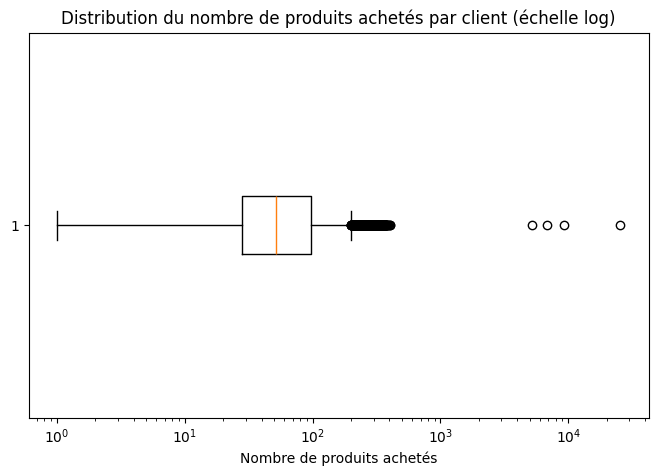

In [29]:
#graphique
plt.figure(figsize=(8, 5))
plt.boxplot(stats_client['nb_produits'], vert=False)
plt.xscale('log')
plt.title("Distribution du nombre de produits achetés par client (échelle log)")
plt.xlabel("Nombre de produits achetés")
plt.show()

In [30]:
# seuil du nombre de produit fixé manuellement à 1000
liste_b2b = stats_client[stats_client['nb_produits'] > 1000]['client_id'].tolist()
print("Nombre de clients B2B:", len(liste_b2b))

Nombre de clients B2B: 4


In [31]:
df_merge['type_client'] = 'B2C'
df_merge.loc[df_merge['client_id'].isin(liste_b2b), 'type_client'] = 'B2B'

In [32]:
df_b2b = df_merge[df_merge['type_client'] == 'B2B']
df_b2c = df_merge[df_merge['type_client'] == 'B2C']
print(df_b2b.groupby('type_client')['client_id'].nunique())

type_client
B2B    4
Name: client_id, dtype: int64


In [33]:
df_merge.head()

,id_prod,date,session_id,client_id,sex,birth,price,categ,age,type_client
0,0_0,2021-03-02 21:57:33.862118,s_908,c_1004,m,1973,3.75,0,48,B2C
1,0_0,2022-02-18 16:40:10.068303,s_167174,c_1011,f,1999,3.75,0,23,B2C
2,0_0,2022-03-18 16:40:10.068303,s_180968,c_1011,f,1999,3.75,0,23,B2C
3,0_0,2022-04-18 16:40:10.068303,s_195932,c_1011,f,1999,3.75,0,23,B2C
4,0_0,2023-02-18 16:40:10.068303,s_343439,c_1011,f,1999,3.75,0,24,B2C


- **df_merge** : table consolidée de 687 534 transactions sans valeur manquante, prête pour les analyses
- **df_b2c** : table consolidée des clients b2c
- **df_b2b** : table consolidée des clients b2b
- **df_clients_na** : Les 21 clients qui n'ont jamais effectué d'achat sur la période et sont exclus de l'analyse
- **df_produits_na** : Les 21 produits qui n'ont jamais été vendus sur la période et sont exclus de l'analyse

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse des indicateurs des ventes</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Analyse des ventes en CA</h3>
</div>

In [34]:
#CA par type de client
ca_client_type = df_merge.groupby('type_client')['price'].sum().reset_index()
ca_client_type.head()

,type_client,price
0,B2B,884296.09
1,B2C,11143367.01


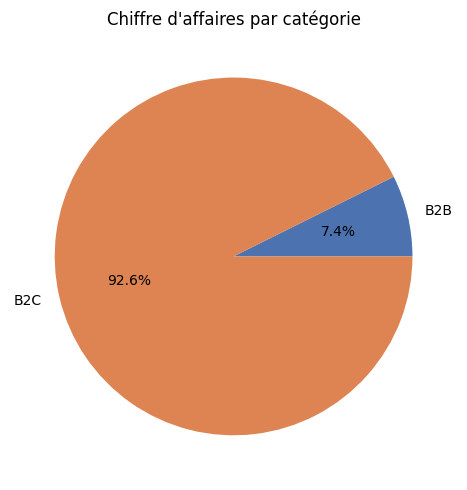

In [35]:
#graphique
plt.figure(figsize=(8, 5))
plt.pie(ca_client_type['price'], labels=ca_client_type['type_client'], colors=['#4C72B0','#DD8452'], autopct='%1.1f%%')
plt.title("Chiffre d'affaires par catégorie")
plt.tight_layout()
plt.show()

Nous observons ici l’évolution du chiffre d’affaires mensuel entre 2021 et 2023.
La moyenne mobile permet de lisser les variations d’un mois à l’autre et de mieux voir la tendance générale.

In [36]:
#CA par mois pour la moyenne mobile
df_merge['mois'] = df_merge['date'].dt.to_period('M')
ca_mois = df_merge.groupby('mois')['price'].sum().reset_index()
ca_mois.columns = ['mois', 'ca']
ca_mois['mois'] = ca_mois['mois'].dt.to_timestamp()
ca_mois = ca_mois.sort_values('mois')
ca_mois.head()

,mois,ca
0,2021-03-01,482440.61
1,2021-04-01,476109.30
2,2021-05-01,492943.47
3,2021-06-01,484088.56
4,2021-07-01,482835.40


In [37]:
#Moyenne mobile
ca_mois['moy_mob_3m'] = ca_mois['ca'].rolling(window=3).mean()
ca_mois['moy_mob'] = ca_mois['ca'].rolling(window=2).mean()
ca_mois.head()

,mois,ca,moy_mob_3m,moy_mob
0,2021-03-01,482440.61,NaN,NaN
1,2021-04-01,476109.30,NaN,479274.955
2,2021-05-01,492943.47,483831.126667,484526.385
3,2021-06-01,484088.56,484380.443333,488516.015
4,2021-07-01,482835.40,486622.476667,483461.980


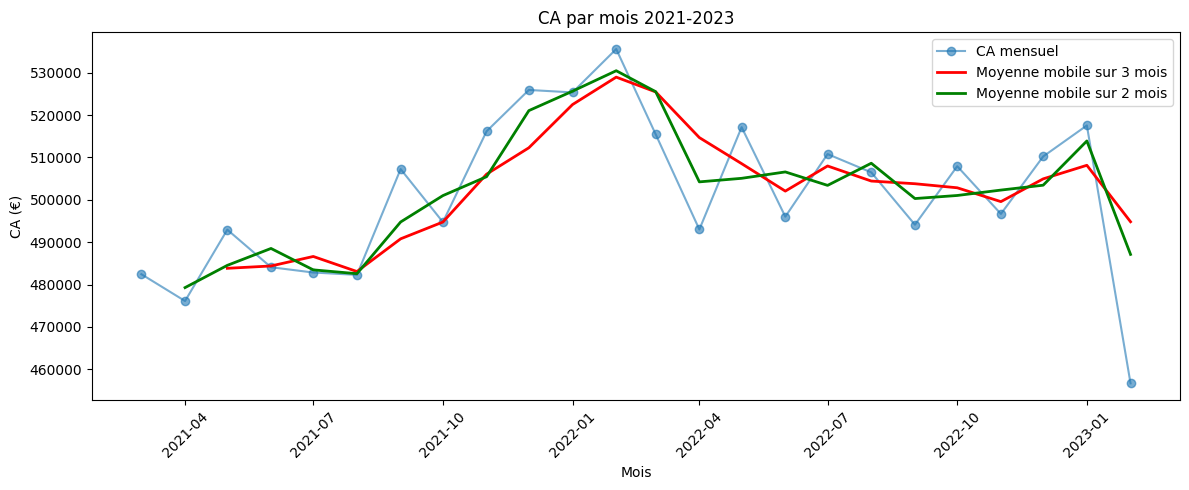

In [38]:
#graphique
plt.figure(figsize=(12, 5))
plt.plot(ca_mois['mois'], ca_mois['ca'], label='CA mensuel', marker='o', alpha=0.6)
plt.plot(ca_mois['mois'], ca_mois['moy_mob_3m'], label='Moyenne mobile sur 3 mois', color='red', linewidth=2)
plt.plot(ca_mois['mois'], ca_mois['moy_mob'], label='Moyenne mobile sur 2 mois', color='green', linewidth=2)
plt.title("CA par mois 2021-2023")
plt.xlabel("Mois")
plt.ylabel("CA (€)")
#plt.ylim(0, 1.2 * ca_mois['ca'].max())
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Le CA total sur 2 ans s'élève à 12 027 663 €. La tendance mensuelle
reste globalement stable, autour de 460 000 à 530 000 par mois, avec un pic vers
janvier-février 2022.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - CA par catégorie de produits</h3>
</div>

Nous répartissons le CA total entre les 3 catégories de produits, pour identifier
celles qui contribuent le plus à l'activité.

In [93]:
#CA par catégorie
ca_categ = df_merge.groupby('categ').agg(ca=('price', 'sum'), nbr_ref=('id_prod', 'nunique')).reset_index()
ca_categ.head()

,categ,ca,nbr_ref
0,0,4419730.97,2292
1,1,4827657.11,737
2,2,2780275.02,236


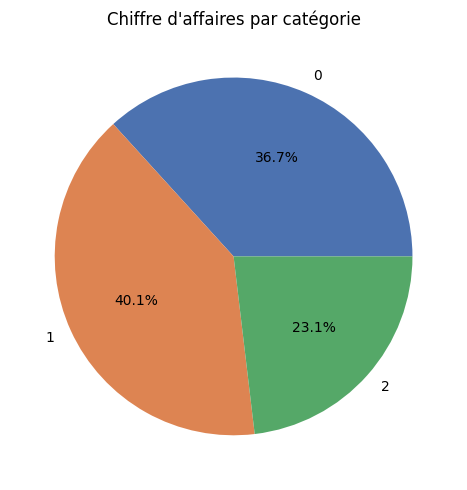

In [94]:
#graphique
plt.figure(figsize=(8, 5))
plt.pie(ca_categ['ca'], labels=ca_categ['categ'].astype(str), colors=['#4C72B0','#DD8452','#55A868'], autopct='%1.1f%%')
plt.title("Chiffre d'affaires par catégorie")
plt.tight_layout()
plt.show()

La catégorie 1 génère le plus de CA, suivie de la catégorie 0.
La catégorie 2 contribue moins au CA car elle propose beaucoup moins de produits que les deux autres catégories.

In [41]:
#CA de chaque catégorie par mois
ca_categ_mois = df_merge.groupby(['mois', 'categ'])['price'].sum().reset_index()
ca_categ_mois.columns = ['mois', 'categ', 'ca']
ca_categ_mois['mois'] = ca_categ_mois['mois'].dt.to_timestamp()

#col par catégorie
ca_categ = ca_categ_mois.pivot(index='mois', columns='categ', values='ca')
ca_categ.head()

categ,0,1,2
mois,,,
2021-03-01,193629.17,186974.17,101837.27
2021-04-01,205222.46,156138.35,114748.49
2021-05-01,196186.72,165893.40,130863.35
2021-06-01,167943.15,189162.04,126983.37
2021-07-01,144750.79,188523.27,149561.34


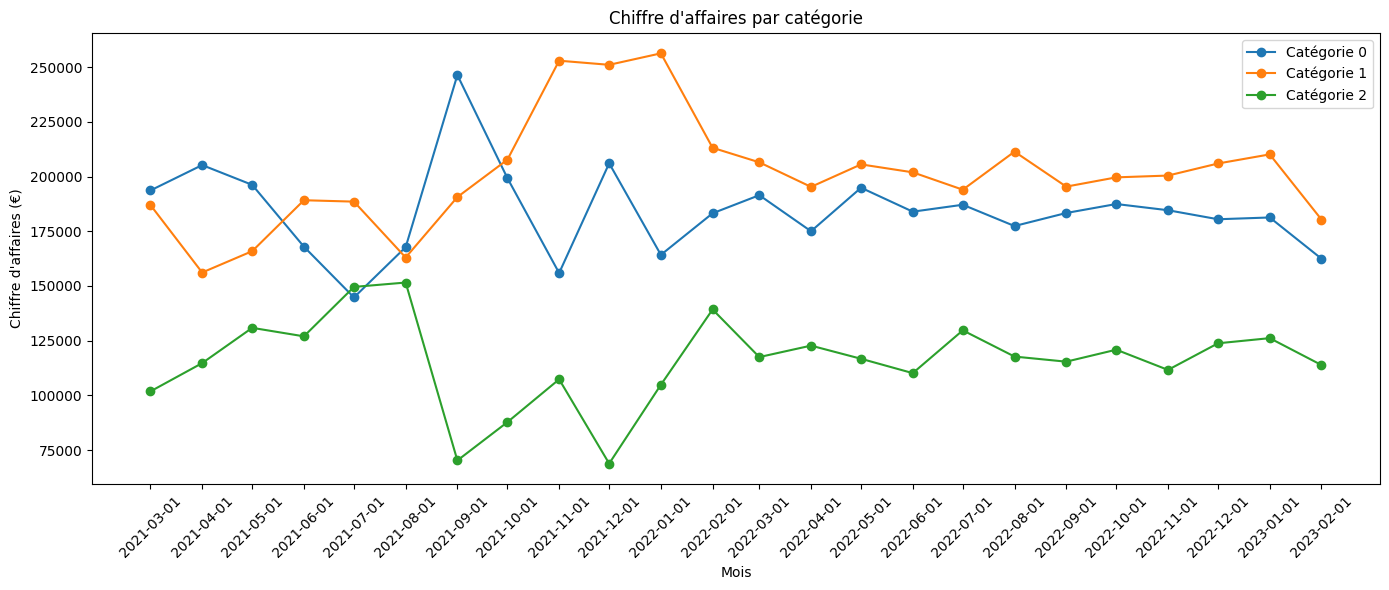

In [42]:
#graphique
plt.figure(figsize=(14, 6))
for categ in ca_categ.columns:plt.plot(ca_categ.index, ca_categ[categ], marker='o', label=f'Catégorie {categ}')
plt.title("Chiffre d'affaires par catégorie")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires (€)")
plt.legend()
plt.xticks(ca_categ.index, rotation=45)
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.3 - Nombre de ventes par catégorie</h3>
</div>

In [92]:
nbr_categ = df_merge.groupby('categ').agg(nbr_prod_vendus=('id_prod', 'count'), nbr_ref=('id_prod', 'nunique')).reset_index()
nbr_categ.head()

,categ,nbr_prod_vendus,nbr_ref
0,0,415459,2292
1,1,235592,737
2,2,36483,236


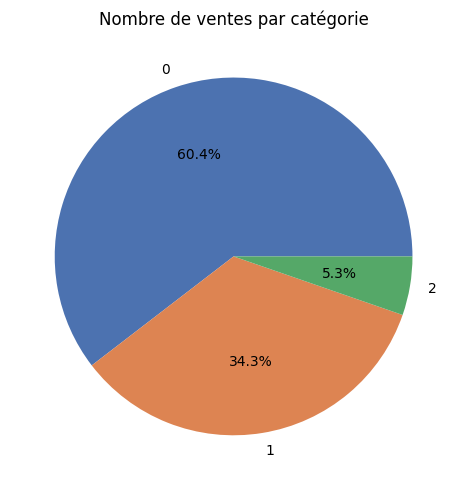

In [44]:
#graphique
plt.figure(figsize=(8, 5))
plt.pie(nbr_categ['nbr_prod_vendus'], labels=nbr_categ['categ'].astype(str), colors=['#4C72B0','#DD8452','#55A868'], autopct='%1.1f%%')
plt.title("Nombre de ventes par catégorie")
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.4 - Volume d'activité</h3>
</div>

Au-delà du CA, nous mesurons le volume d'activité mensuel pour évaluer la régularité de l'activité
dans le temps.

In [45]:
#Volume d'activité par mois
volume_mois = df_merge.groupby('mois').agg(nb_transactions=('session_id', 'nunique'), nb_produits_vendus=('id_prod', 'count'), nb_clients=('client_id', 'nunique')).reset_index()
volume_mois['mois'] = volume_mois['mois'].dt.to_timestamp()
volume_mois.head()

,mois,nb_transactions,nb_produits_vendus,nb_clients
0,2021-03-01,14201,28601,5676
1,2021-04-01,13970,28443,5674
2,2021-05-01,14168,28285,5644
3,2021-06-01,13838,26850,5659
4,2021-07-01,13571,24738,5672


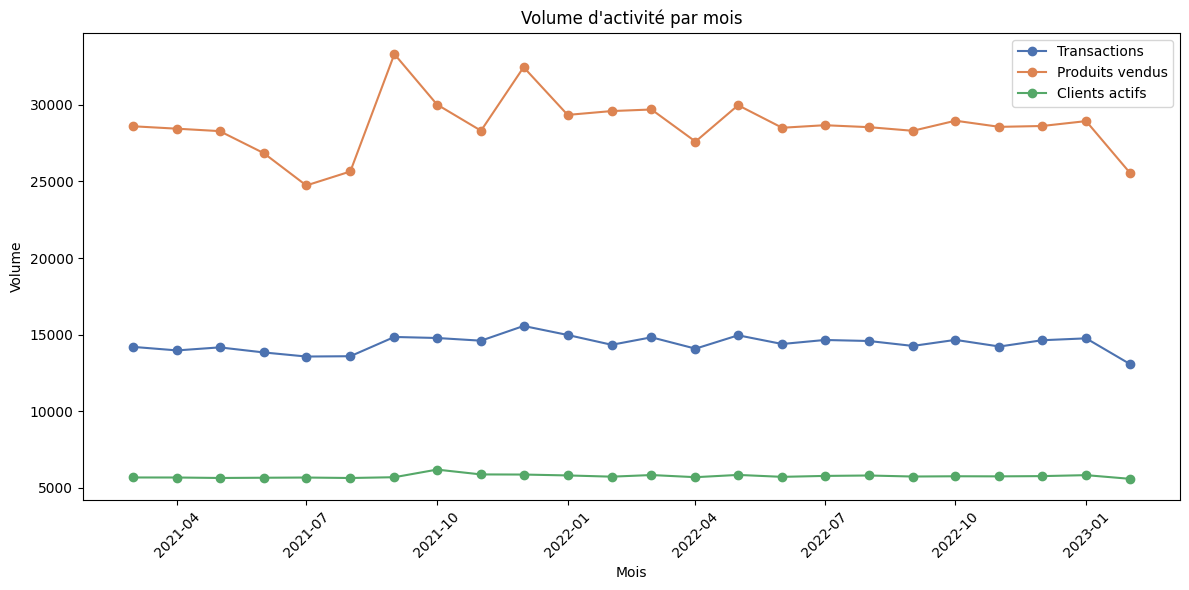

In [46]:
#graphique
plt.figure(figsize=(12, 6))
plt.plot(volume_mois['mois'], volume_mois['nb_transactions'], marker='o', color='#4C72B0', label='Transactions')
plt.plot(volume_mois['mois'], volume_mois['nb_produits_vendus'], marker='o', color='#DD8452', label='Produits vendus')
plt.plot(volume_mois['mois'], volume_mois['nb_clients'], marker='o', color='#55A868', label='Clients actifs')

plt.title("Volume d'activité par mois")
plt.xlabel("Mois")
plt.ylabel("Volume")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

Le volume d'activité est globalement stable dans le temps.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.5 - Tops et flops des produits en CA</h3>
</div>

Nous identifions les 10 produits générant le plus et le moins de chiffre d'affaires

In [47]:
# Ventes (quantité et CA) par produit
produit_ca = df_merge.groupby(['id_prod', 'categ']).agg(quantite=('id_prod', 'count'), ca=('price', 'sum')).reset_index()
produit_ca.head()

,id_prod,categ,quantite,ca
0,0_0,0,1242,4657.50
1,0_1,0,487,5352.13
2,0_10,0,22,394.90
3,0_100,0,3,61.80
4,0_1000,0,432,2954.88


In [48]:
#TOP 10 des produits les mieux vendus en CA
top10_ca = produit_ca.sort_values('ca', ascending=False).head(10)
top10_sorted_ca = top10_ca.sort_values('ca', ascending=True)

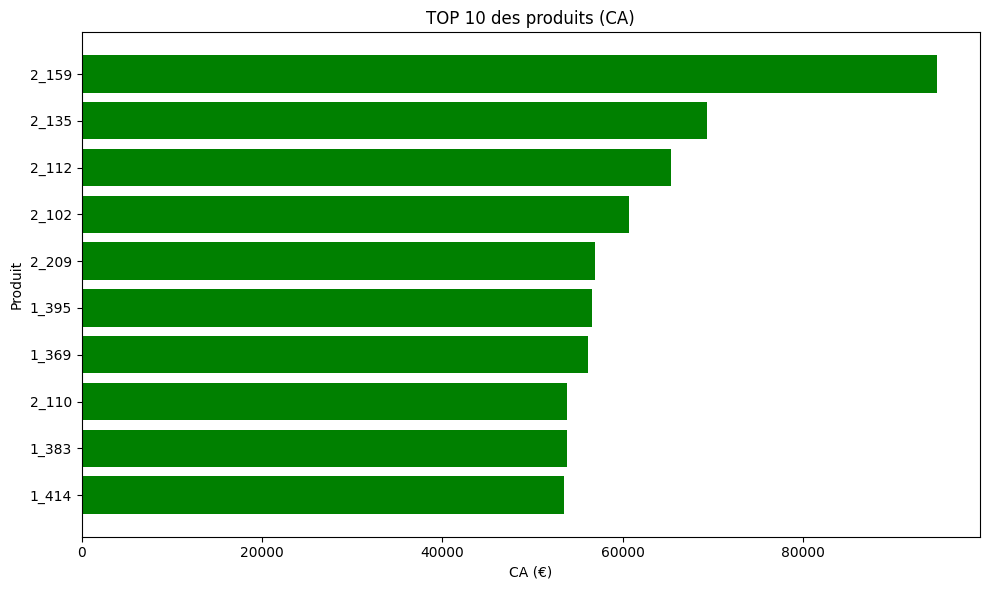

In [49]:
#graphique
plt.figure(figsize=(10, 6))
plt.barh(top10_sorted_ca['id_prod'].astype(str), top10_sorted_ca['ca'], color='green')
plt.xlabel("CA (€)")
plt.ylabel("Produit")
plt.title("TOP 10 des produits (CA)")
plt.tight_layout()
plt.show()

In [50]:
#FLOP 10 des produits les moins vendus en CA
flop10_ca = produit_ca.sort_values('ca', ascending=True).head(10)
flop10_sorted_ca = flop10_ca.sort_values('ca', ascending=False)

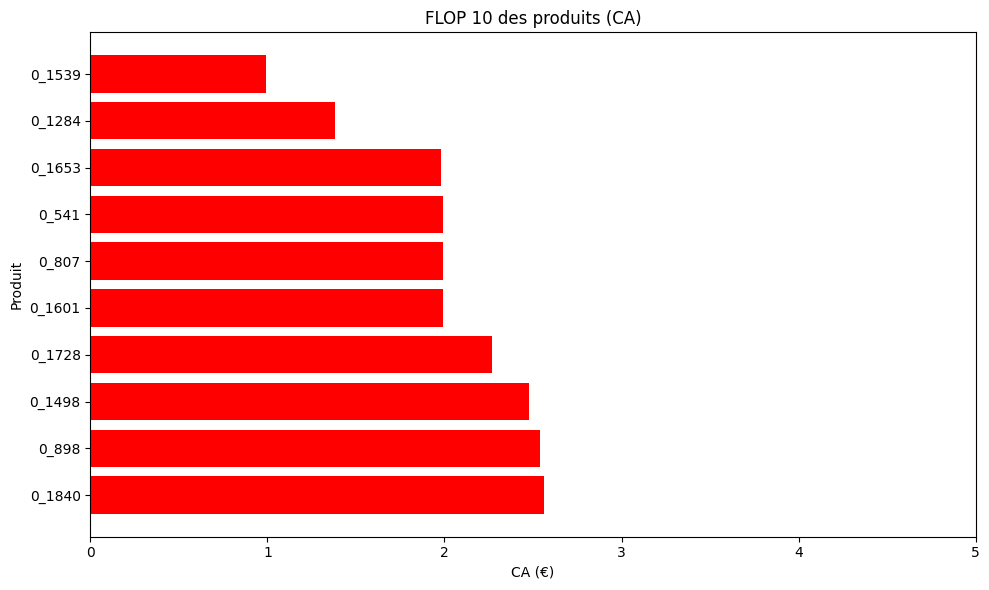

In [51]:
#graphique
plt.figure(figsize=(10, 6))
plt.barh(flop10_sorted_ca['id_prod'].astype(str), flop10_sorted_ca['ca'], color='red')
plt.xlim(0, 5)
plt.xlabel("CA (€)")
plt.ylabel("Produit")
plt.title("FLOP 10 des produits (CA)")
plt.tight_layout()
plt.show()

Le flop 10 ci‑dessus ne montre que les produits vendus au moins une fois.
Il existe aussi **21 produits** du catalogue qui n’ont jamais été vendus sur la période 2021‑2023 qu'on retrouve dans la table **df_produits_na**.
Ce sont les véritables flops absolus

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.6 - Tops et flops des produits en quantité</h3>
</div>

 En complément de l'analyse en CA, nous regardons les produits les plus et les moins
vendus en quantité.

In [52]:
#TOP 10 des produits les plus vendus en quantité
top10 = produit_ca.sort_values('quantite', ascending=False).head(10)
top10_sorted = top10.sort_values('quantite', ascending=True)

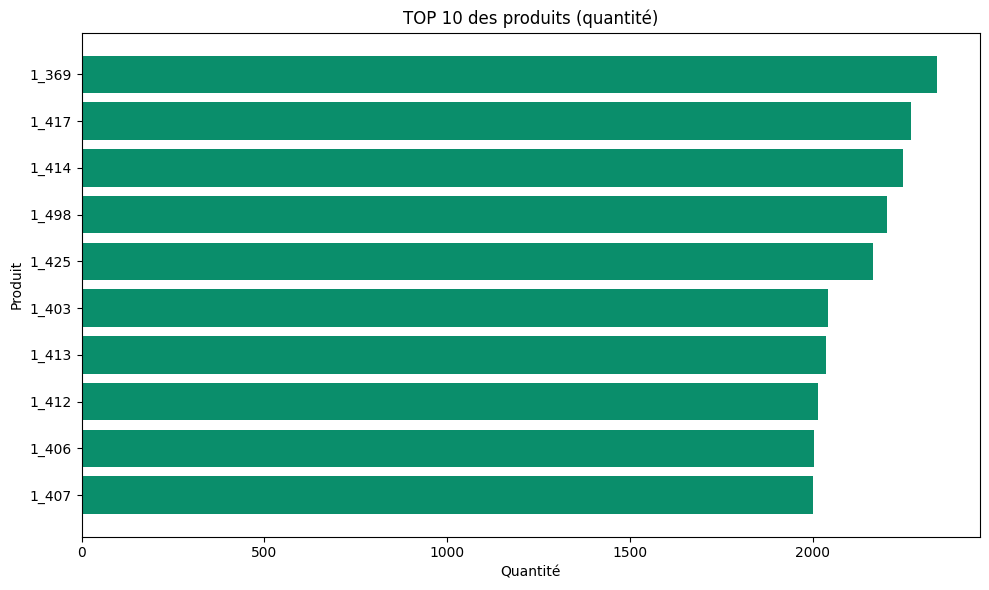

In [53]:
#graphique
plt.figure(figsize=(10, 6))
plt.barh(top10_sorted['id_prod'].astype(str), top10_sorted['quantite'], color='#0A8E6B')
plt.xlabel("Quantité")
plt.ylabel("Produit")
plt.title("TOP 10 des produits (quantité)")
plt.tight_layout()
plt.show()

In [54]:
#FLOP 10 des produits les moins vendus en quantité
flop10 = produit_ca.sort_values('quantite', ascending=True).head(10)
flop10_sorted = flop10.sort_values('quantite', ascending=False)

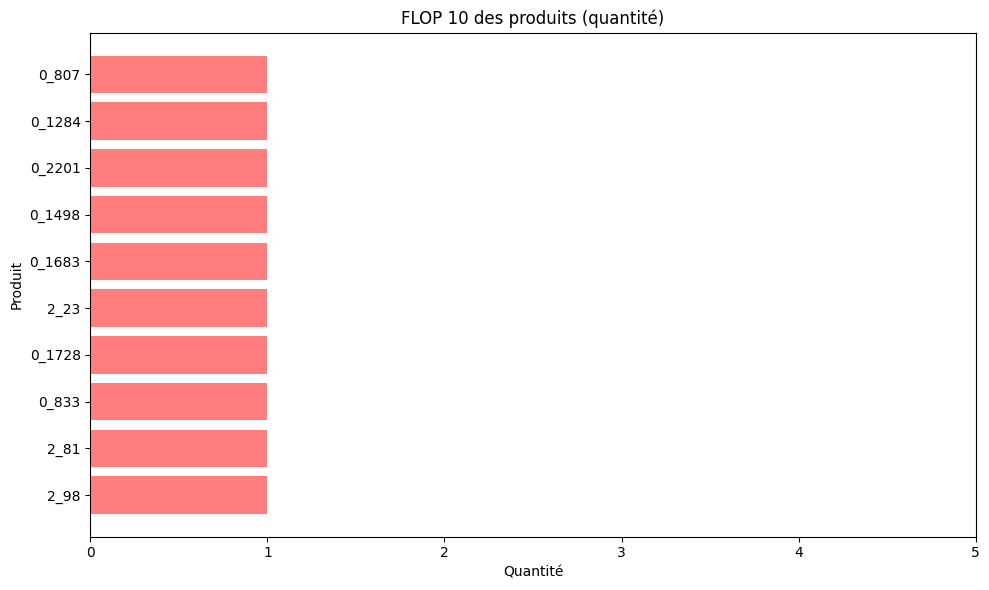

In [55]:
#graphique
plt.figure(figsize=(10, 6))
plt.barh(flop10_sorted['id_prod'].astype(str), flop10_sorted['quantite'], color='#FF7D7D')
plt.xlim(0, 5)
plt.xlabel("Quantité")
plt.ylabel("Produit")
plt.title("FLOP 10 des produits (quantité)")
plt.tight_layout()
plt.show()

Le flop 10 ci‑dessus ne montre que les produits vendus au moins une fois. Il existe aussi **21 produits** du catalogue qui n’ont jamais été vendus sur la période 2021‑2023 qu'on retrouve dans la table **df_produits_na**. Ce sont les véritables flops absolus

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Profil client</h2>
</div>

In [56]:
#Répartiion par type de client
nb_type = df_merge.groupby('type_client')['client_id'].nunique().reset_index(name='nb')
print(nb_type)

  type_client    nb
0         B2B     4
1         B2C  8596


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Répartition des clients par genre</h3>
</div>

In [57]:
#Répartition des clients par genre
repartition_genre = df_merge.groupby('client_id')['sex'].first().value_counts()
print(repartition_genre)

sex
f    4479
m    4121
Name: count, dtype: int64


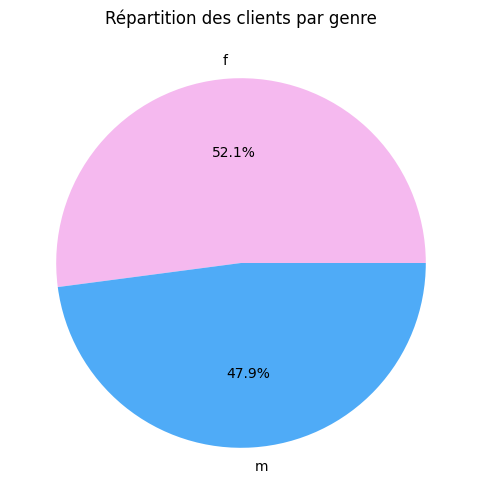

In [58]:
#graphique
plt.figure(figsize=(6, 6))
plt.pie(repartition_genre, labels=repartition_genre.index, autopct='%1.1f%%', colors=['#F5B9EF','#4FABF7'])
plt.title("Répartition des clients par genre")
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Répartition des clients par âge</h3>
</div>

In [59]:
#Répartition des clients par âge
age_client = df_merge.groupby('client_id')['age'].first()
print(age_client.describe())

count    8600.000000
mean       42.894767
std        16.912414
min        17.000000
25%        29.000000
50%        42.000000
75%        55.000000
max        93.000000
Name: age, dtype: float64


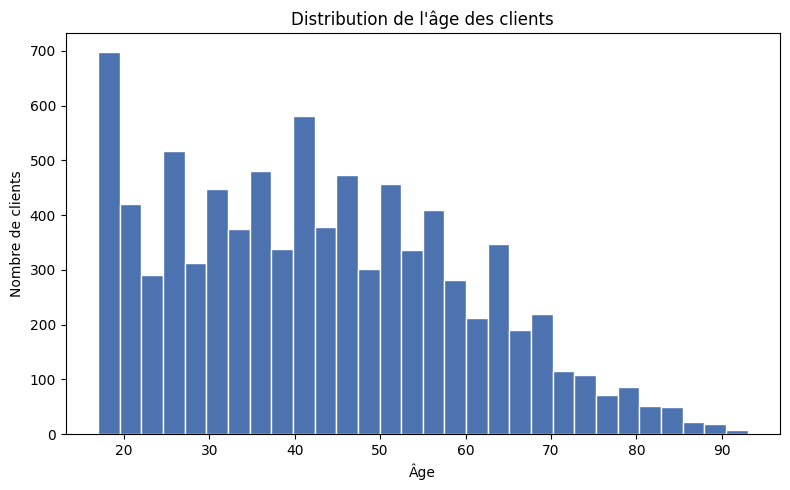

In [60]:
#graphique
plt.figure(figsize=(8, 5))
plt.hist(age_client, bins=30, color='#4C72B0', edgecolor='white')
plt.title("Distribution de l'âge des clients")
plt.xlabel("Âge")
plt.ylabel("Nombre de clients")
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Top 10 des meilleurs clients</h3>
</div>

In [61]:
#Top 10 meilleurs clients
top_client = (df_b2c.groupby('client_id').agg(ca=('price', 'sum'),age=('age', 'first')).sort_values('ca', ascending=True)).reset_index()
top_client = top_client.sort_values('ca', ascending=False).head(10)
top10_sorted_clients = top_client.sort_values('ca', ascending=True)
top10_sorted_clients.head(10)

,client_id,ca,age
8586,c_2505,5059.35,39
8587,c_8026,5082.58,43
8588,c_7421,5097.18,43
8589,c_1422,5131.36,41
8590,c_7959,5135.75,47
8591,c_7319,5155.77,47
8592,c_2899,5214.05,27
8593,c_2140,5260.18,45
8594,c_3263,5276.87,36
8595,c_1570,5285.82,42


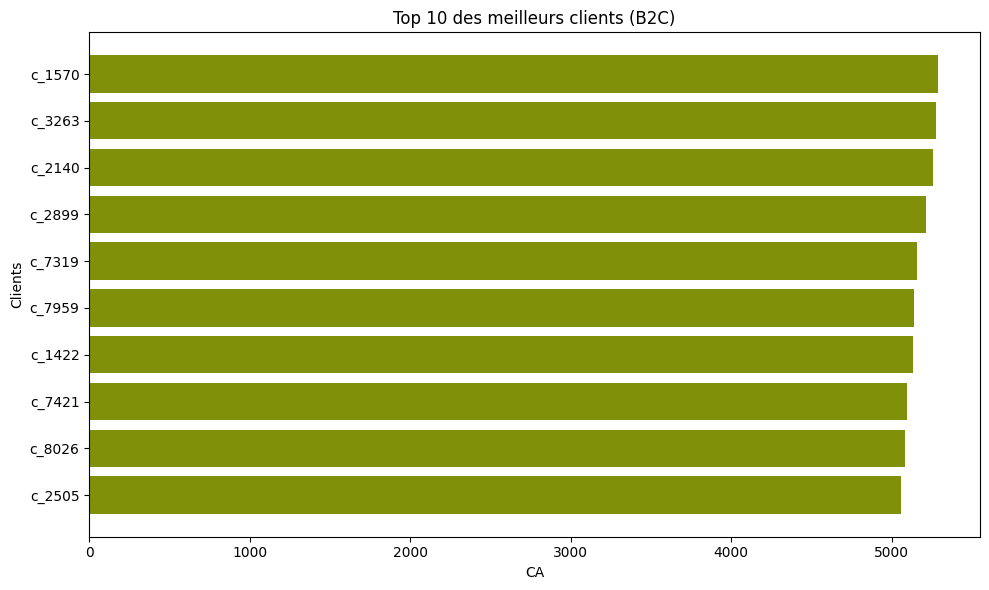

In [62]:
#graphique
plt.figure(figsize=(10, 6))
plt.barh(top10_sorted_clients['client_id'].astype(str), top10_sorted_clients['ca'], color='#809008')
plt.xlabel("CA")
plt.ylabel("Clients")
plt.title("Top 10 des meilleurs clients (B2C)")
plt.tight_layout()
plt.show()

En complément de ce classement des meilleurs clients, il est à noter que **21 clients**
inscrits n'ont jamais réalisé d'achat sur la période 2021-2023 dans la table
**df_clients_na**

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Courbe de Lorenz</h3>
</div>

Pour mieux comprendre le comportement d'achat de nos clients, nous étudions la
répartition du chiffre d'affaires entre eux à l'aide de la courbe de Lorenz. Cet outil
permet de visualiser si le CA est réparti équitablement entre tous les clients ou si
une minorité de clients concentre l'essentiel des ventes

In [63]:
ca_client = df_merge.groupby('client_id')['price'].sum().sort_values()

#Courbe de lorenz
n = len(ca_client)

#prop cumulées
lorenz = np.cumsum(ca_client) / ca_client.sum()
lorenz = np.insert(lorenz, 0, 0)
x = np.linspace(0, 1, len(lorenz))

#Gini
aire = (lorenz.sum() - lorenz[-1]/2 - lorenz[0]/2) / n
gini = 2 * (0.5 - aire)
print("Indice de Gini:", round(gini, 3))

Indice de Gini: 0.442


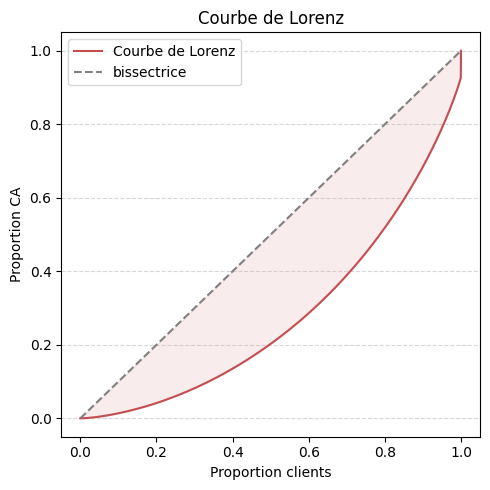

In [64]:
#graphique
plt.figure(figsize=(5, 5))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.plot(x, lorenz, label='Courbe de Lorenz', color='#C44E52')
plt.plot([0, 1], [0, 1], label='bissectrice', linestyle='--', color='gray')
plt.fill_between(x, lorenz, x, color='#C44E52', alpha=0.1)
plt.title(f"Courbe de Lorenz")
plt.xlabel("Proportion clients")
plt.ylabel("Proportion CA")
plt.legend()
plt.tight_layout()
plt.show()

L'indice de Gini de 0.442 indique une concentration modérée à significative du chiffre
d'affaires, environ 20% des clients génèrent 50% du CA total. Cette concentration
s'explique en partie par la présence de 4 comptes B2B, dont le volume d'achat est très
supérieur à celui des clients particuliers.

In [65]:
#Courbe de lorenz des clients B2C
ca_client_b2c = df_b2c.groupby('client_id')['price'].sum().sort_values()
n = len(ca_client_b2c)

#prop cumulées
lorenz_b2c = np.cumsum(ca_client_b2c) / ca_client_b2c.sum()
lorenz_b2c = np.insert(lorenz_b2c, 0, 0)  # on part de (0,0)
x = np.linspace(0, 1, len(lorenz_b2c))

#Gini
aire = (lorenz_b2c.sum() - lorenz_b2c[-1]/2 - lorenz_b2c[0]/2) / n
gini = 2 * (0.5 - aire)
print("Indice de Gini:", round(gini, 3))

Indice de Gini: 0.398


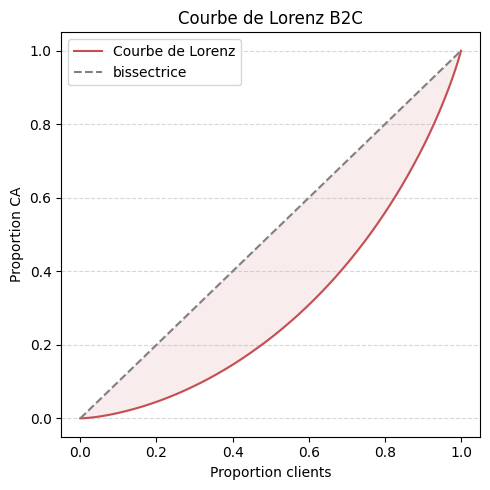

In [66]:
#graphique
plt.figure(figsize=(5, 5))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.plot(x, lorenz_b2c, label='Courbe de Lorenz', color='#C44E52')
plt.plot([0, 1], [0, 1], label='bissectrice', linestyle='--', color='gray')
plt.fill_between(x, lorenz_b2c, x, color='#C44E52', alpha=0.1)
plt.title(f"Courbe de Lorenz B2C")
plt.xlabel("Proportion clients")
plt.ylabel("Proportion CA")
plt.legend()
plt.tight_layout()
plt.show()

En retirant les 4 clients B2B, l’indice de Gini baisse à 0,398.  
Cela montre que les comptes B2B augmentent la concentration du chiffre d’affaires.
Mais même sans eux, certains clients achètent beaucoup plus que les autres, donc une petite concentration reste normale.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - Étude corrélations</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.1 -  Genre client et catégories de livres achetés </h3>
</div>

- H0 : le genre du client et la catégorie de livres achetés sont indépendants
- H1 : le genre du client et la catégorie de livres achetés sont liés

In [101]:
tab_contingence = pd.crosstab(df_b2c['sex'], df_b2c['categ'])
print(tab_contingence)

chi2, p_value, dof, expected = stats.chi2_contingency(tab_contingence)
print(f"Chi2 = {chi2:.2f}")
print(f"p-value = {p_value:.4f}")

categ       0       1      2
sex                         
f      200793  115721  16980
m      186488  104884  15868
Chi2 = 22.67
p-value = 0.0000


**Résultat** : Chi2 = 22.67, p-value = 0.0000 < 0.05
- H0 rejetée. Il existe un lien
statistiquement significatif entre le genre et la catégorie achetée.

La p-value extrêmement faible s'explique par la taille gigantesque de notre échantillon (plus de 640 000 transactions), ce qui rend le test du Chi-deux ultra-sensible

In [68]:
# Calcul du V de Cramér
n = tab_contingence.sum().sum()
v_cramer = np.sqrt(chi2 / (n * (min(tab_contingence.shape) - 1)))
print(f"V de Cramer = {v_cramer:.4f}")

V de Cramer = 0.0059


Mais le V de Cramer = 0.006 qui est quasi nul, montre un lien négligeable en pratique.


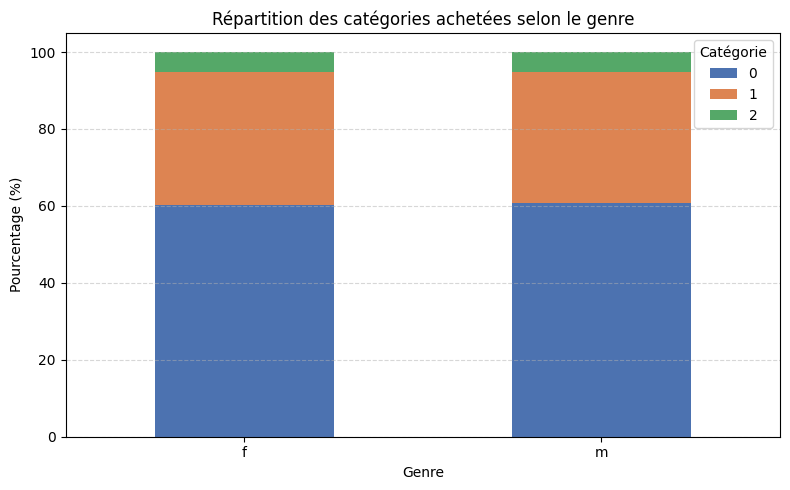

In [69]:
contingence_pct = tab_contingence.div(tab_contingence.sum(axis=1), axis=0) * 100

contingence_pct.plot(kind='bar', stacked=True, figsize=(8,5), color=['#4C72B0','#DD8452','#55A868'])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.title("Répartition des catégories achetées selon le genre")
plt.ylabel("Pourcentage (%)")
plt.xlabel("Genre")
plt.legend(title='Catégorie')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Conclusion**: Le genre n'est pas un critère pertinent pour cibler des offres par
catégorie de produit

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.2 -  Âge clients et montant total des achats </h3>
</div>

In [97]:
montant_client = df_b2c.groupby('client_id').agg(age=('age', 'first'), montant_total=('price', 'sum')).reset_index()
montant_client.head()

,client_id,age,montant_total
0,c_1,66,629.02
1,c_10,65,1353.60
2,c_100,29,254.85
3,c_1000,56,2291.88
4,c_1001,39,1823.85


Avant chaque test de corrélation, il est nécessaire de vérifier si les variables suivent une loi normale, afin de choisir le test statistique adapté :
- si la normalité est validée: test paramétrique (Pearson, ANOVA)
- si la normalité est rejetée: test non-paramétrique (Spearman, Kruskal-Wallis)

La fonction `loi_normale()` automatise ce test de Kolmogorov-Smirnov.

**Hypothèses testées :**
- H0 : la variable suit une loi normale
- H1 : la variable ne suit pas une loi normale

La fonction affiche le résultat H0 acceptée ou
rejetée selon la p-value obtenue.

In [95]:
def loi_normale(colonne, nom):
    z_col = stats.zscore(colonne)
    stat, p_value = stats.kstest(z_col, 'norm')
    print(f"Kolmogorov-Smirnov pour {nom}: \n statistique = {stat:.4f}\n p-value = {p_value:.4f}")
    if p_value < 0.05:
      print("H1 : la variable ne suit pas une loi normale\n")
    else:
      print("H0 : la variable suit une loi normale")

In [96]:
loi_normale(montant_client['age'], "l'âge")
loi_normale(montant_client['montant_total'], 'le montant total')

Kolmogorov-Smirnov pour l'âge: 
 statistique = 0.0629
 p-value = 0.0000
H1 : la variable ne suit pas une loi normale

Kolmogorov-Smirnov pour le montant total: 
 statistique = 0.1059
 p-value = 0.0000
H1 : la variable ne suit pas une loi normale



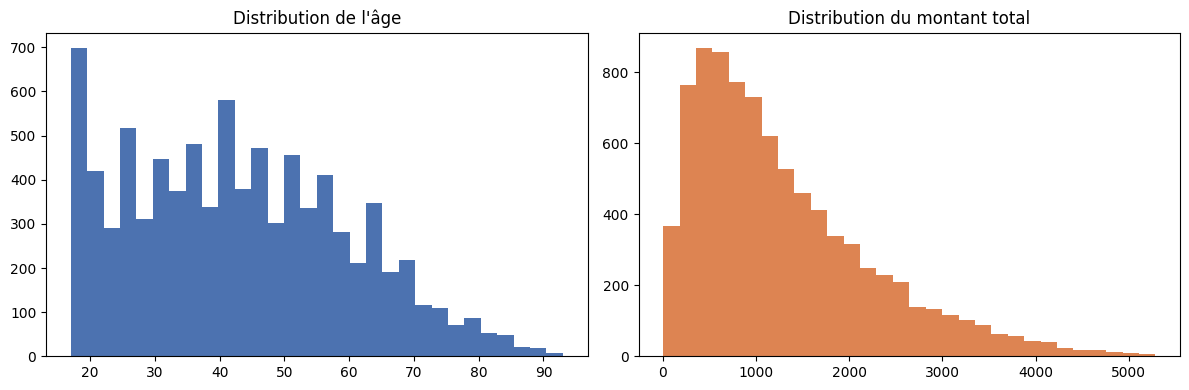

In [73]:
#distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(montant_client['age'], bins=30, color='#4C72B0')
axes[0].set_title("Distribution de l'âge")
axes[1].hist(montant_client['montant_total'], bins=30, color='#DD8452')
axes[1].set_title("Distribution du montant total")
plt.tight_layout()
plt.show()

Les deux variables rejettent l'hypothèse de normalité la p-value < 0.05.
Nous utiliserons le test non-paramétrique
de Spearman.

**Hypothèses testées :**
- H0 : il n'existe pas de corrélation entre l'âge du client et le montant total de ses achats
- H1 : il existe une corrélation entre l'âge du client et le montant total de ses achats

In [74]:
#test de Spearman
coef, p = stats.spearmanr(montant_client['age'], montant_client['montant_total'])
print("Coefficient de Spearman =", coef)
print(f"p-value = {p:.4f}")

Coefficient de Spearman = -0.18454511453208125
p-value = 0.0000


La p-value = 0.0000 < 0.05, on rejette H0.

Il existe une corrélation statistiquement significative entre l'âge des clients et le
montant total de leurs achats. Le signe négatif indique que plus
l'âge augmente, plus le montant total dépensé diminue.

L'âge seul
n'explique donc qu'une petite partie des écarts de montant total entre clients.

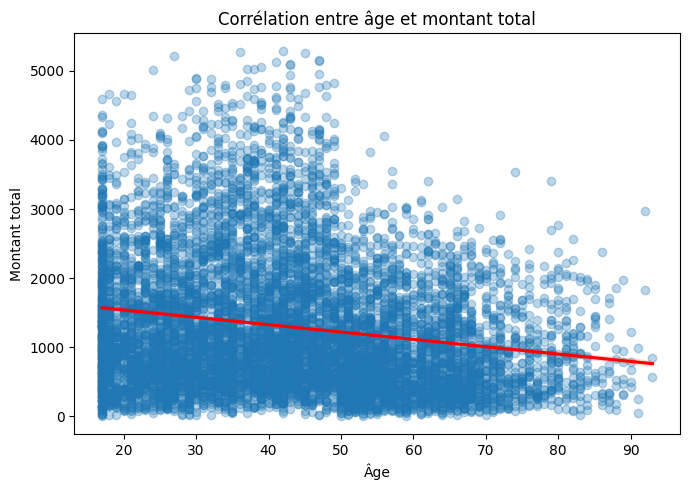

In [75]:
#graphique
plt.figure(figsize=(7, 5))
sns.regplot(data=montant_client, x='age', y='montant_total', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title("Corrélation entre âge et montant total")
plt.xlabel("Âge")
plt.ylabel("Montant total")
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.3 -  Âge clients et fréquence d'achat </h3>
</div>

In [76]:
frequence_client = df_b2c.groupby('client_id').agg(age=('age', 'first'), nb_transactions=('session_id', 'nunique')).reset_index()
frequence_client.head()

,client_id,age,nb_transactions
0,c_1,66,34
1,c_10,65,34
2,c_100,29,5
3,c_1000,56,94
4,c_1001,39,47


**Hypothèses testées :**
- H0 : la variable suit une loi normale
- H1 : la variable ne suit pas une loi normale

In [77]:
# Test loi normale
loi_normale(frequence_client['age'], 'âge')
loi_normale(frequence_client['nb_transactions'], 'fréquence d\'achat')

Kolmogorov-Smirnov pour âge: 
 statistique = 0.0629
 p-value = 0.0000

H1 : la variable ne suit pas une loi normale
Kolmogorov-Smirnov pour fréquence d'achat: 
 statistique = 0.1524
 p-value = 0.0000

H1 : la variable ne suit pas une loi normale


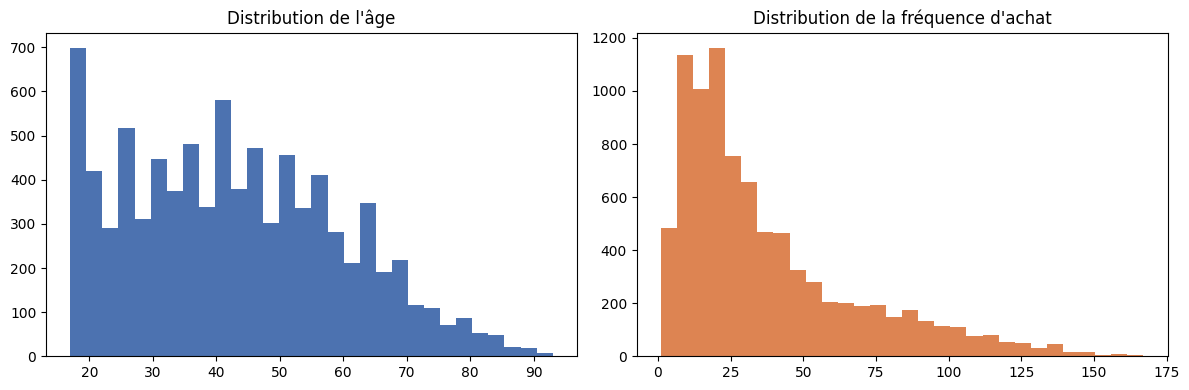

In [78]:
#distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(frequence_client['age'], bins=30, color='#4C72B0')
axes[0].set_title("Distribution de l'âge")
axes[1].hist(frequence_client['nb_transactions'], bins=30, color='#DD8452')
axes[1].set_title("Distribution de la fréquence d'achat")
plt.tight_layout()
plt.show()

Les deux variables rejettent l'hypothèse de normalité la p-value < 0.05.
Nous utiliserons le test non-paramétrique
de Spearman.

**Hypothèses testées :**
- H0 : il n'existe pas de corrélation entre l'âge du client et sa fréquence d'achat
- H1 : il existe une corrélation entre l'âge du client et sa fréquence d'achat

In [79]:
#Corrélation Spearman
coef, p = stats.spearmanr(frequence_client['age'], frequence_client['nb_transactions'])
print("Coefficient de Spearman =", coef)
print(f"p-value = {p:.4f}")

Coefficient de Spearman = 0.2117921037159671
p-value = 0.0000


La p-value = 0.0000 < 0.05, on rejette H0.

Il existe une corrélation statistiquement significative entre l'âge des clients et leur
fréquence d'achat. Le signe positif indique une relation directe : plus l'âge augmente,
plus la fréquence d'achat a tendance à augmenter légèrement.

L'âge seul n'explique donc
qu'une petite partie des écarts de fréquence d'achat entre clients.

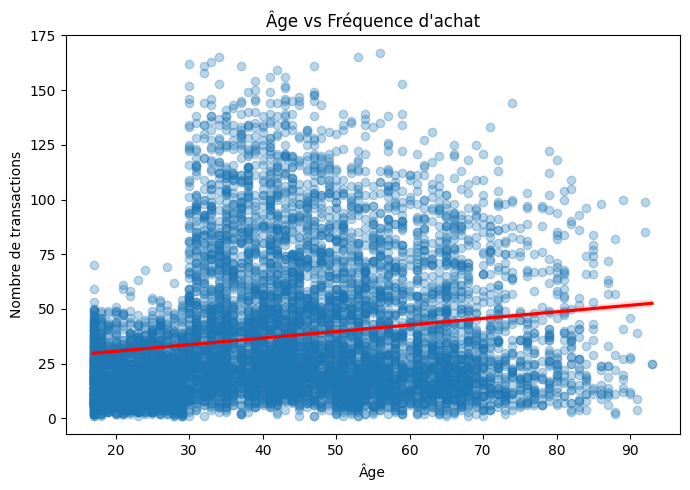

In [80]:
#graphique
plt.figure(figsize=(7, 5))
sns.regplot(data=frequence_client, x='age', y='nb_transactions', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title("Âge vs Fréquence d'achat")
plt.xlabel("Âge")
plt.ylabel("Nombre de transactions")
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.4 -   Âge clients et taille du panier moyen </h3>
</div>

In [81]:
# groupby session
panier = df_b2c.groupby(['client_id', 'session_id'])['price'].sum().reset_index()
panier.columns = ['client_id', 'session_id', 'montant_panier']

# groupby moyenne
panier_moyen_client = panier.groupby('client_id')['montant_panier'].mean().reset_index()
panier_moyen_client.columns = ['client_id', 'panier_moyen']

# df avec l'âge
age_client = df_b2c.groupby('client_id')['age'].first().reset_index()
panier_moyen_client = panier_moyen_client.merge(age_client, on='client_id')

panier_moyen_client.head()

,client_id,panier_moyen,age
0,c_1,18.500588,66
1,c_10,39.811765,65
2,c_100,50.970000,29
3,c_1000,24.381702,56
4,c_1001,38.805319,39


**Hypothèses testées :**
- H0 : la variable suit une loi normale
- H1 : la variable ne suit pas une loi normale

In [82]:
# Test loi normale
loi_normale(panier_moyen_client['age'], 'âge')
loi_normale(panier_moyen_client['panier_moyen'], 'panier moyen')

Kolmogorov-Smirnov pour âge: 
 statistique = 0.0629
 p-value = 0.0000

H1 : la variable ne suit pas une loi normale
Kolmogorov-Smirnov pour panier moyen: 
 statistique = 0.1875
 p-value = 0.0000

H1 : la variable ne suit pas une loi normale


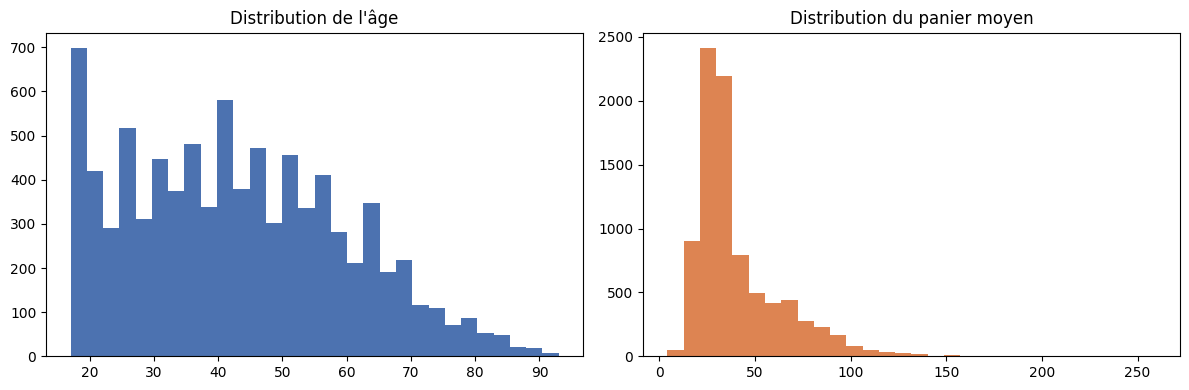

In [83]:
#distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(panier_moyen_client['age'], bins=30, color='#4C72B0')
axes[0].set_title("Distribution de l'âge")
axes[1].hist(panier_moyen_client['panier_moyen'], bins=30, color='#DD8452')
axes[1].set_title("Distribution du panier moyen")
plt.tight_layout()
plt.show()

Les deux variables rejettent l'hypothèse de normalité la p-value < 0.05.
Nous utiliserons le test non-paramétrique
de Spearman.

**Hypothèses testées :**

- H0 : il n'existe pas de corrélation entre l'âge du client et la taille de son panier moyen
- H1 : il existe une corrélation entre l'âge du client et la taille de son panier moyen

In [84]:
# Corrélation Spearman
coef, p = stats.spearmanr(panier_moyen_client['age'], panier_moyen_client['panier_moyen'])
print("Coefficient de Spearman =", coef)
print(f"p-value = {p:.4f}")

Coefficient de Spearman = -0.7001527860968529
p-value = 0.0000


La p-value = 0.0000 < 0.05, on rejette H0.

Il existe une corrélation statistiquement significative et forte entre l'âge des clients
et la taille de leur panier moyen. Le signe négatif indique que
plus un client est âgé, plus son panier moyen a tendance à être petit.

Le coefficient de spearman étant fort = -0,7 rend ce résultat  exploitable pour orienter des recommandations ou des offres adaptées
selon l'âge du client.

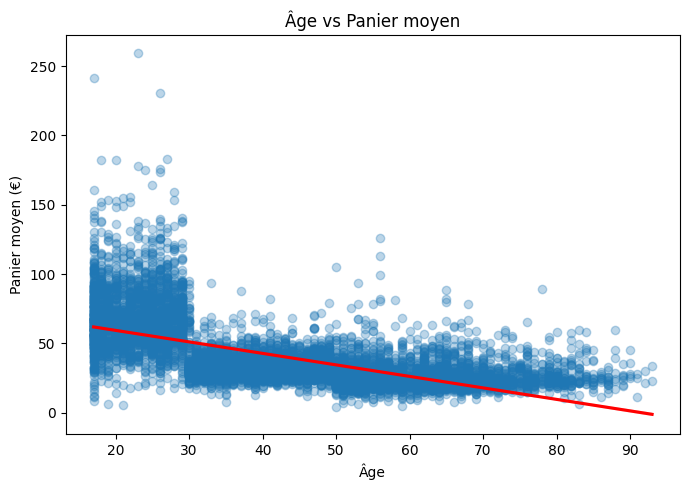

In [85]:
#graphique
plt.figure(figsize=(7, 5))
sns.regplot(data=panier_moyen_client, x='age', y='panier_moyen', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title("Âge vs Panier moyen")
plt.xlabel("Âge")
plt.ylabel("Panier moyen (€)")
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 6.5 -  Âge clients et catégorie de livres achetés </h3>
</div>

In [99]:
groupe_0 = df_b2c[df_b2c['categ'] == 0]['age']
groupe_1 = df_b2c[df_b2c['categ'] == 1]['age']
groupe_2 = df_b2c[df_b2c['categ'] == 2]['age']

**Hypothèses testées :**
- H0 : la variable suit une loi normale
- H1 : la variable ne suit pas une loi normale

In [100]:
loi_normale(groupe_0, 'âge - catégorie 0')
loi_normale(groupe_1, 'âge - catégorie 1')
loi_normale(groupe_2, 'âge - catégorie 2')

Kolmogorov-Smirnov pour âge - catégorie 0: 
 statistique = 0.1105
 p-value = 0.0000
H1 : la variable ne suit pas une loi normale

Kolmogorov-Smirnov pour âge - catégorie 1: 
 statistique = 0.0431
 p-value = 0.0000
H1 : la variable ne suit pas une loi normale

Kolmogorov-Smirnov pour âge - catégorie 2: 
 statistique = 0.2347
 p-value = 0.0000
H1 : la variable ne suit pas une loi normale



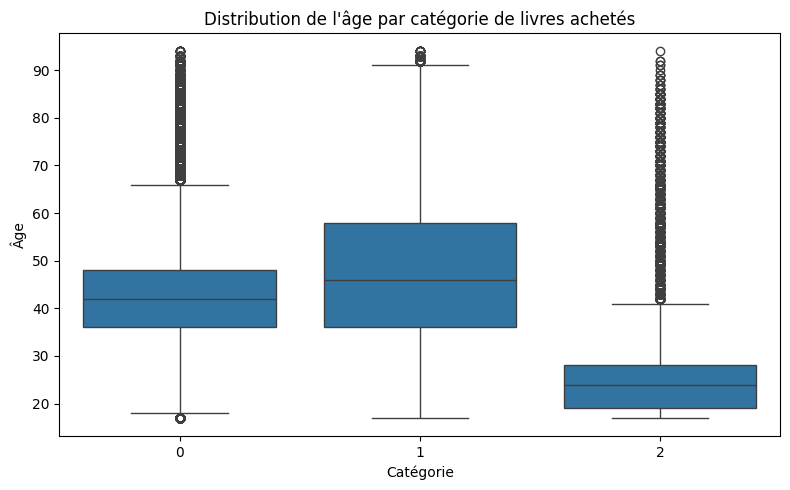

In [88]:
#graphique
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_b2c, x='categ', y='age')
plt.title("Distribution de l'âge par catégorie de livres achetés")
plt.xlabel("Catégorie")
plt.ylabel("Âge")
plt.tight_layout()
plt.show()

L'âge des clients ne suivant pas une loi normale, comme nous l'avons vu lors du test de Kolmogorov-Smirnov, p-value < 0,05 (on rejette H0).
Nous appliquons le test non paramétrique de **Kruskal-Wallis** pour comparer la distribution des âges à travers les 3 catégories de livres.

**Hypothèses testées :**
- H0 : il n'existe pas de lien entre l'âge et la catégorie de livres achetée
- H1 : il existe un lien entre l'âge et la catégorie de livres achetée

In [89]:
h_stat, p_value_kw = stats.kruskal(groupe_0, groupe_1, groupe_2)
print(f"Kruskal-Wallis : H = {h_stat:.2f}, p-value = {p_value_kw:.4f}")

Kruskal-Wallis : H = 71283.58, p-value = 0.0000


In [90]:
print(df_b2c.groupby('categ')['age'].median())
print(df_b2c.groupby('categ')['age'].mean())

categ
0    42.0
1    46.0
2    24.0
Name: age, dtype: float64
categ
0    43.446784
1    47.325840
2    25.652764
Name: age, dtype: float64


La p-value = 0.0000 < 0.05, on rejette H0.

L'âge des clients diffère significativement selon la catégorie de livres achetée. Les
catégories 0 et 1 touchent un public plus mature de 42-46 ans en médiane, tandis que la
catégorie 2 attire un public plus jeune de 23 ans en médiane, un écart
d'environ 20 ans qui pourrait orienter des campagnes marketing ciblées par tranche
d'âge selon la catégorie.

**Conclusion:**

- Cibler les campagnes marketing par âge plutôt que par genre, notamment pour la catégorie 2 auprès d'un public jeune
- Adapter l'offre selon l’âge, par exemple des formules d'abonnement/fidélité pour les clients âgés qui achètent souvent mais peu à la fois
- Formaliser une offre B2B dédiée, vu leur poids disproportionné dans le CA malgré leur faible nombre